
# Intelligent Predictive Maintenance & Machine Failure Risk Management

## 1. Problem Understanding

### Business Problem
Unexpected machine failures cause production delays, increased maintenance costs, and operational disruptions. Fixed maintenance schedules may result in unnecessary servicing or missed failures.

### Objective
Predict machine failure risk using operational sensor data to support maintenance planning and inspection prioritization.

### Prediction Task
- Problem Type: Binary Classification
- Target: Machine failure
- 0: No Failure
- 1: Failure

### Project Approach
1. Understand, audit, and prepare the dataset.
2. Explore sensor patterns and class imbalance.
3. Develop Logistic Regression, Random Forest, and ANN models.
4. Evaluate model reliability and prediction errors.
5. Conduct a controlled ANN experiment.
6. Recommend a suitable model and maintenance strategy.

### Expected Outcome
A reliable and reproducible machine failure risk prediction solution that supports evidence-based maintenance decisions.




## 2. CBIM Canvas — Predictive Maintenance

| Component | Description |
|---|---|
| Business Problem | Unexpected machine failures disrupt production and increase maintenance costs. |
| Stakeholders | Maintenance team, production managers, and manufacturing management. |
| Business Objective | Reduce unexpected failures and improve maintenance prioritization. |
| Current Process | Fixed preventive maintenance schedules. |
| Proposed Solution | Predict machine failure risk using ML and ANN models. |
| Data Available | Product type, temperatures, rotational speed, torque, and tool wear. |
| AI Task | Binary classification (0 = No Failure, 1 = Failure). |
| Success Metrics | Recall, Precision, F1, ROC-AUC, PR-AUC, and error costs. |
| Business Decision | Prioritize inspections based on predicted failure risk. |
| Key Risks | Missed failures, false alarms, class imbalance, and data leakage. |
| Constraints | Synthetic dataset, no true machine-level time series, and unknown real maintenance costs. |
| Expected Value | Better maintenance decisions and potentially reduced downtime and unnecessary inspections. |

### Key Business Priority
Identify as many actual failures as practical while controlling unnecessary inspections and their costs.

### Assumption
Actual maintenance costs are unavailable. Any cost-based analysis will use clearly labeled hypothetical values.



## 3. Dataset Loading and Initial Inspection

**Dataset:** AI4I 2020 Predictive Maintenance Dataset (UCI)

The dataset contains machine operating measurements and failure information.

**Objective:**
- Load the dataset.
- Check the number of rows and columns.
- Display the first five records.
- Identify available features and the target column.

No preprocessing or cleaning is performed at this stage.


In [1]:

import pandas as pd

df = pd.read_csv("ai4i2020.csv")

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

display(df.head())


C:\Users\madhu\AppData\Roaming\Python\Python312\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\madhu\AppData\Roaming\Python\Python312\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


Dataset Shape: (10000, 14)

Column Names:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0



## 4. Dataset Structure and Data Types

We examine the dataset to understand:
- Data types of each column.
- Missing values.
- Number of unique values.
- Basic dataset information.

This helps identify potential data-quality issues before preprocessing.


In [2]:

print("Dataset Information:")
df.info()

print("\nMissing Values:")
display(df.isnull().sum().to_frame("Missing Count"))

print("\nUnique Values:")
display(df.nunique().to_frame("Unique Count"))


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3)

,Missing Count
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0



Unique Values:


,Unique Count
UDI,10000
Product ID,10000
Type,3
Air temperature [K],93
Process temperature [K],82
Rotational speed [rpm],941
Torque [Nm],577
Tool wear [min],246
Machine failure,2
TWF,2



# Phase 1 — Business Understanding, Data Audit and Preparation

In this phase, we understand the business problem, inspect dataset quality, explore machine operating patterns, and prepare the data for modeling.

**Main activities:**
- Business understanding and CBIM Canvas
- Dataset inspection and data-quality checks
- Exploratory Data Analysis (EDA)
- Class imbalance and sensor relationship analysis
- Leakage-free preprocessing



### 5. Duplicate and Category Validation

We check for duplicate records and verify whether product types and target labels contain valid values.


In [3]:

print("Duplicate Rows:", df.duplicated().sum())

print("\nProduct Type Distribution:")
print(df["Type"].value_counts(dropna=False))

print("\nTarget Values:")
print(df["Machine failure"].value_counts(dropna=False))

print("\nInvalid Product Types:",
      (~df["Type"].isin(["L", "M", "H"])).sum())

print("Invalid Target Values:",
      (~df["Machine failure"].isin([0, 1])).sum())


Duplicate Rows: 0

Product Type Distribution:
Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

Target Values:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Invalid Product Types: 0
Invalid Target Values: 0



**Findings:**
- No duplicate records or invalid categories were found.
- Product types: L (60%), M (29.97%), H (10.03%).
- Failures represent only 3.39% of records.
- The target is highly imbalanced, so accuracy alone is insufficient.
- Class imbalance must be considered during model training and evaluation.



### 6. Sensor Validity and Descriptive Statistics

We examine sensor ranges, summary statistics, and invalid readings to identify possible data-quality issues before cleaning.


In [4]:

sensor_cols = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

display(df[sensor_cols].describe().T.round(2))

print("\nNon-finite values:")
print((~np.isfinite(df[sensor_cols])).sum() if "np" in globals()
      else "NumPy not imported yet")

print("\nNon-positive readings:")
for col in sensor_cols:
    print(f"{col}: {(df[col] <= 0).sum()}")

print("\nProcess Temperature Below Air Temperature:",
      (df["Process temperature [K]"] < df["Air temperature [K]"]).sum())


,count,mean,std,min,25%,50%,75%,max
Air temperature [K],10000.0,300.00,2.00,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,310.01,1.48,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,1538.78,179.28,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,39.99,9.97,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,107.95,63.65,0.0,53.0,108.0,162.0,253.0



Non-finite values:
NumPy not imported yet

Non-positive readings:
Air temperature [K]: 0
Process temperature [K]: 0
Rotational speed [rpm]: 0
Torque [Nm]: 0
Tool wear [min]: 120

Process Temperature Below Air Temperature: 0



**Findings:**
- Sensor values are within plausible preliminary ranges.
- No non-positive temperature, speed, or torque readings were found.
- Tool wear has 120 zero values, which may be valid.
- Process temperature is always above air temperature.
- Extreme sensor readings require further investigation before cleaning.



### 7. Non-Finite Values and Outlier Detection

We check for infinite sensor values and identify potential outliers using the IQR method.

Outliers will be investigated before deciding whether treatment is necessary.


In [5]:

import numpy as np

print("Non-finite values:")
print((~np.isfinite(df[sensor_cols])).sum())

outliers = []

for col in sensor_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    outliers.append({
        "Sensor": col,
        "Outliers": count,
        "Percentage": round(count / len(df) * 100, 2)
    })

display(pd.DataFrame(outliers))


Non-finite values:
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
dtype: int64


,Sensor,Outliers,Percentage
0,Air temperature [K],0,0.00
1,Process temperature [K],0,0.00
2,Rotational speed [rpm],418,4.18
3,Torque [Nm],69,0.69
4,Tool wear [min],0,0.00



**Findings:**
- No infinite or missing sensor values were found.
- Rotational speed has 418 outliers (4.18%).
- Torque has 69 outliers (0.69%).
- Other sensors have no IQR outliers.
- Outliers are retained for now because extreme conditions may indicate machine failure.



### 8. Outlier Impact on Machine Failure

We compare failure rates for normal and outlier sensor readings to understand whether extreme operating conditions are associated with machine failures.


In [6]:

for col in ["Rotational speed [rpm]", "Torque [Nm]"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1

    outlier = (df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)

    result = df.groupby(outlier)["Machine failure"].agg(
        Records="count",
        Failures="sum",
        Failure_Rate="mean"
    )

    result.index = result.index.map({False: "Normal", True: "Outlier"})
    result["Failure_Rate"] = (result["Failure_Rate"] * 100).round(2)

    print(f"\n{col}")
    display(result)



Rotational speed [rpm]


,Records,Failures,Failure_Rate
Rotational speed [rpm],,,
Normal,9582,304,3.17
Outlier,418,35,8.37



Torque [Nm]


,Records,Failures,Failure_Rate
Torque [Nm],,,
Normal,9931,277,2.79
Outlier,69,62,89.86



**Findings:**
- Rotational speed outliers have an 8.37% failure rate, compared with 3.17% for normal readings.
- Torque outliers have an 89.86% failure rate, compared with 2.79% for normal readings.
- Extreme sensor readings show strong associations with machine failure.
- We retain these observations because removing them could discard valuable failure patterns.
- These are associations, not proof of causation.



### 9. Sensor Distribution Analysis

We use histograms and boxplots to understand sensor distributions, variability, skewness, and extreme operating readings.


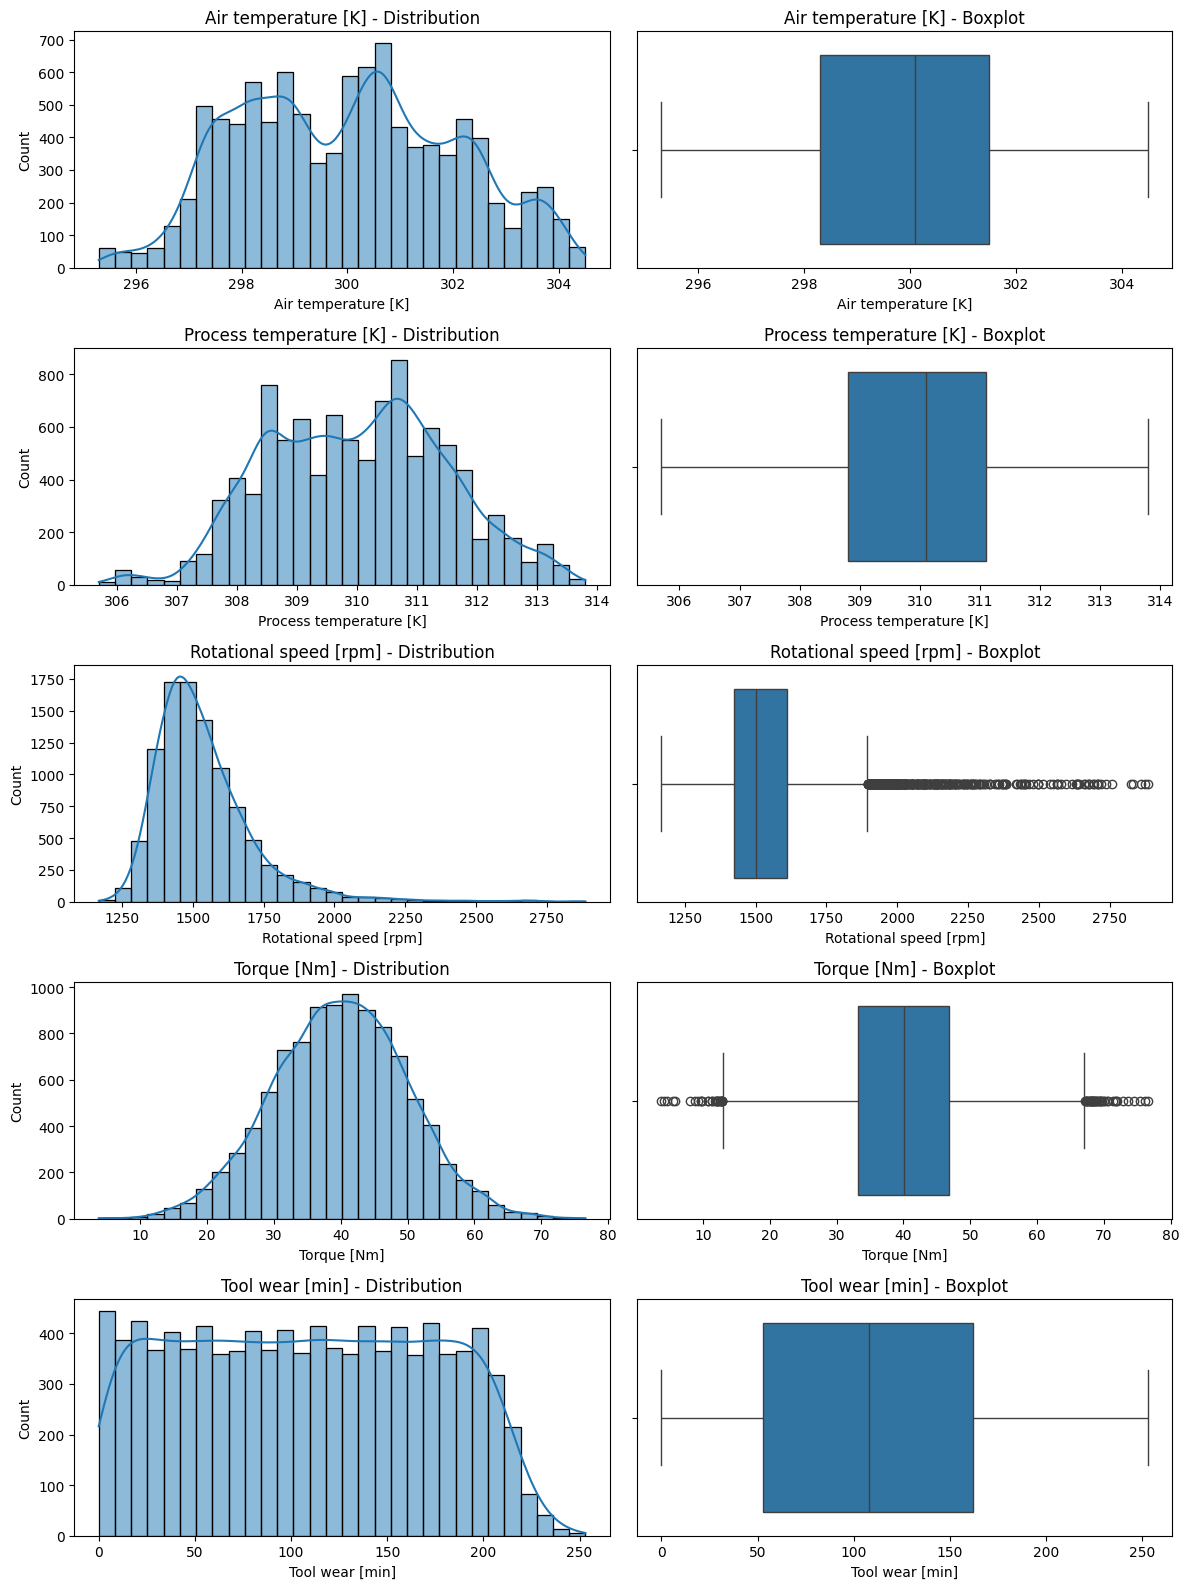

In [7]:

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(5, 2, figsize=(12, 16))

for i, col in enumerate(sensor_cols):
    sns.histplot(df[col], bins=30, kde=True, ax=axes[i, 0])
    axes[i, 0].set_title(f"{col} - Distribution")

    sns.boxplot(x=df[col], ax=axes[i, 1])
    axes[i, 1].set_title(f"{col} - Boxplot")

plt.tight_layout()
plt.show()



**Findings:**
- Air and process temperatures show multiple peaks without IQR outliers.
- Rotational speed is right-skewed with several high-value outliers.
- Torque is approximately bell-shaped with outliers at both ends.
- Tool wear is broadly distributed without IQR outliers.
- Extreme sensor readings are retained for failure prediction.



### 10. Sensor Patterns by Machine Failure

We compare sensor measurements between failed and non-failed records to identify operating conditions associated with machine failure.


,No Failure,Failure
Air temperature [K],299.97,300.89
Process temperature [K],310.00,310.29
Rotational speed [rpm],1540.26,1496.49
Torque [Nm],39.63,50.17
Tool wear [min],106.69,143.78


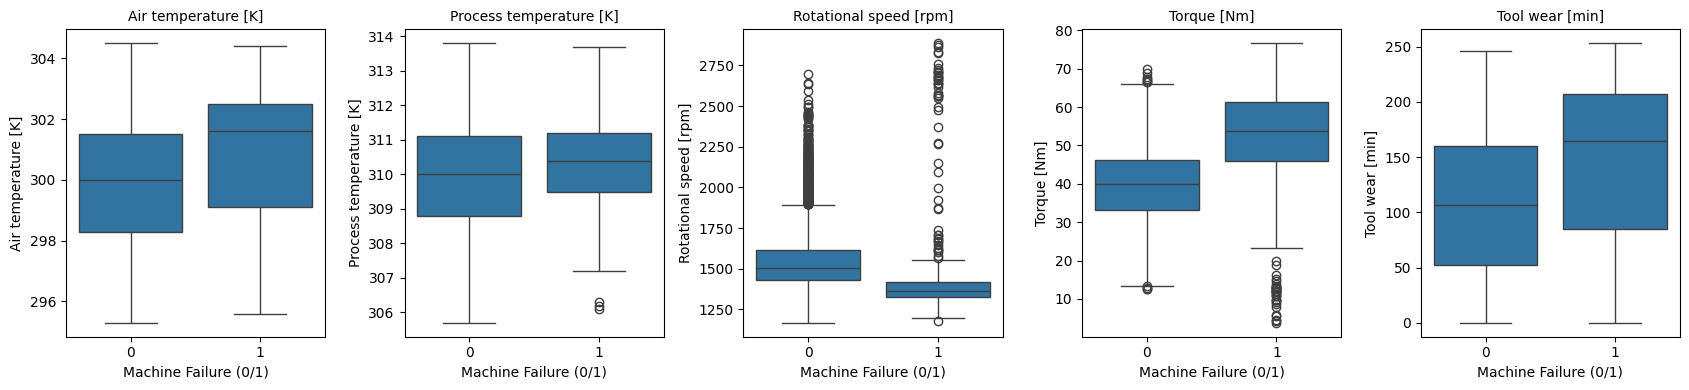

In [8]:

failure_summary = df.groupby("Machine failure")[sensor_cols].mean().T
failure_summary.columns = ["No Failure", "Failure"]

display(failure_summary.round(2))

fig, axes = plt.subplots(1, 5, figsize=(17, 4))

for i, col in enumerate(sensor_cols):
    sns.boxplot(data=df, x="Machine failure", y=col, ax=axes[i])
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel("Machine Failure (0/1)")

plt.tight_layout()
plt.show()



**Findings:**
- Failed records have higher average torque (50.17 vs 39.63 Nm).
- Tool wear is higher during failures (143.78 vs 106.69 min).
- Air temperature is slightly higher in failed records.
- Rotational speed is lower on average during failures, but extreme high speeds also occur.
- Process temperature shows a smaller average difference.
- These patterns suggest associations, not causation.



### 11. Sensor Correlation Analysis

We calculate correlations between numerical sensors and machine failure to identify linear relationships and highly related features.


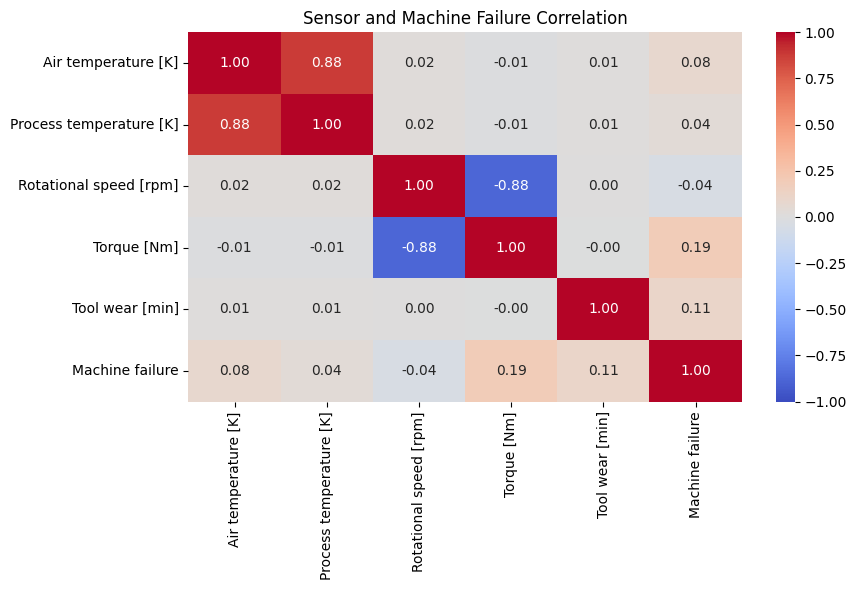

In [9]:

corr_cols = sensor_cols + ["Machine failure"]

corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(9, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm",
            fmt=".2f", vmin=-1, vmax=1)

plt.title("Sensor and Machine Failure Correlation")
plt.tight_layout()
plt.show()



**Findings:**
- Air and process temperatures show strong positive correlation (+0.88).
- Rotational speed and torque show strong negative correlation (-0.88).
- Torque (+0.19) and tool wear (+0.11) have the highest positive linear correlations with failure.
- Individual sensor correlations with failure are relatively weak.
- All five sensors are retained initially because nonlinear interactions may provide useful information.



### 12. Product Type and Machine Failure

We compare failure rates across product types (L, M, H) to identify possible associations between product quality category and machine failure.


,Records,Failures,Failure_Rate
Type,,,
H,1003,21,2.09
L,6000,235,3.92
M,2997,83,2.77


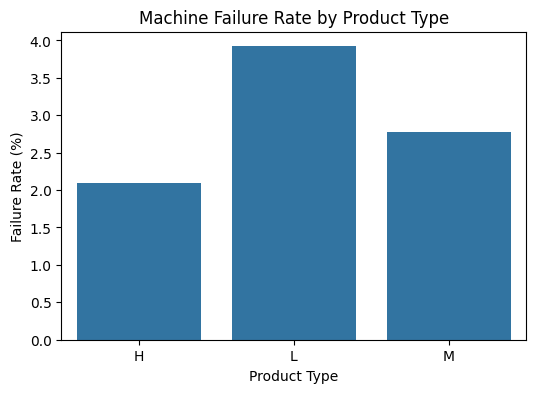

In [10]:

type_summary = df.groupby("Type")["Machine failure"].agg(
    Records="count",
    Failures="sum",
    Failure_Rate="mean"
)

type_summary["Failure_Rate"] = (
    type_summary["Failure_Rate"] * 100
).round(2)

display(type_summary)

plt.figure(figsize=(6, 4))
sns.barplot(x=type_summary.index,
            y=type_summary["Failure_Rate"])

plt.title("Machine Failure Rate by Product Type")
plt.xlabel("Product Type")
plt.ylabel("Failure Rate (%)")
plt.show()



**Findings:**
- Type L has the highest failure rate (3.92%).
- Type M has a failure rate of 2.77%.
- Type H has the lowest failure rate (2.09%).
- Product type shows an association with machine failure.
- We retain Type as a categorical feature for modeling.



### 13. Sensor Interaction Analysis

We examine how rotational speed, torque, and temperature difference relate to machine failure.

This helps identify possible nonlinear patterns and useful features for modeling.


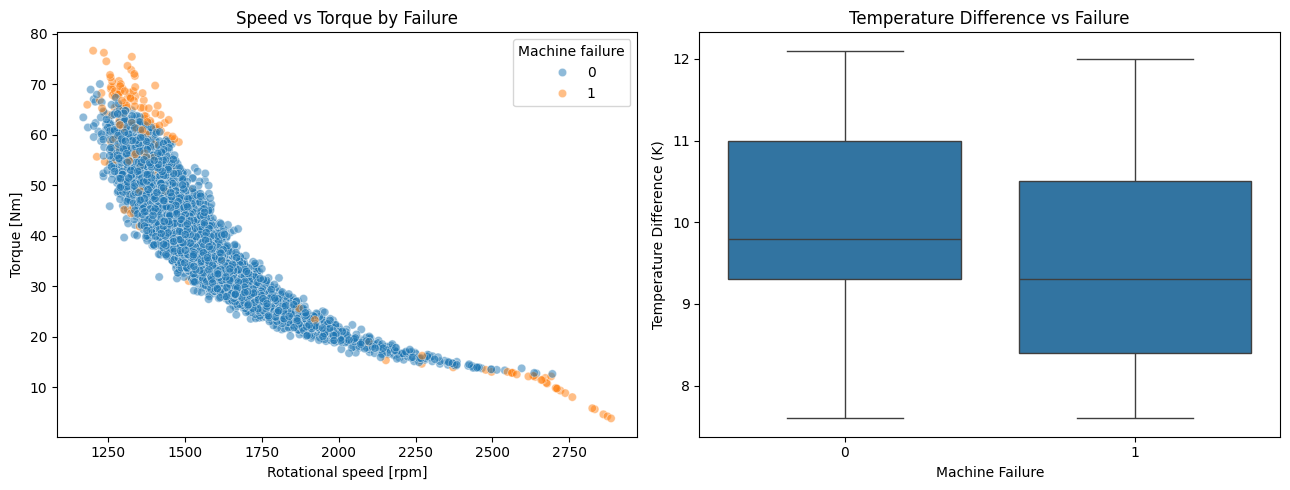

In [11]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(
    data=df, x="Rotational speed [rpm]", y="Torque [Nm]",
    hue="Machine failure", alpha=0.5, ax=axes[0]
)
axes[0].set_title("Speed vs Torque by Failure")

temp_difference = df["Process temperature [K]"] - df["Air temperature [K]"]

sns.boxplot(x=df["Machine failure"], y=temp_difference, ax=axes[1])
axes[1].set_title("Temperature Difference vs Failure")
axes[1].set_ylabel("Temperature Difference (K)")
axes[1].set_xlabel("Machine Failure")

plt.tight_layout()
plt.show()



**Findings:**
- Rotational speed and torque show a strong inverse relationship.
- Failures appear more frequently at extreme speed-torque combinations.
- Failed records generally show a lower temperature difference.
- Temperature difference may provide useful additional information.
- These patterns are associations, not proof of causation.



### 14. Feature Engineering Investigation

We explore temperature difference and a speed-torque interaction feature to capture operating patterns that individual sensors may not fully represent.


In [12]:

feature_analysis = pd.DataFrame({
    "Temperature_Difference": (
        df["Process temperature [K]"] - df["Air temperature [K]"]
    ),
    "Speed_Torque_Product": (
        df["Rotational speed [rpm]"] * df["Torque [Nm]"]
    ),
    "Machine failure": df["Machine failure"]
})

display(
    feature_analysis.groupby("Machine failure").agg(
        ["mean", "median", "std"]
    ).round(2)
)

print("\nCorrelation with Machine Failure:")
display(
    feature_analysis.corr()["Machine failure"].round(3)
)


Temperature_Difference              Speed_Torque_Product  \
                                  mean median   std                 mean   
Machine failure                                                            
0                                10.02    9.8  0.99             59631.04   
1                                 9.40    9.3  1.16             69545.80   

                                    
                  median       std  
Machine failure                     
0                59616.7   9658.11  
1                72683.8  17677.07


Correlation with Machine Failure:


Temperature_Difference   -0.112
Speed_Torque_Product      0.176
Machine failure           1.000
Name: Machine failure, dtype: float64


**Findings:**
- Failed records have a lower average temperature difference (9.40 K vs 10.02 K).
- Failed records have a higher speed-torque product (69,545.80 vs 59,631.04).
- Both features show associations with machine failure.
- We will evaluate these candidate features during model development.
- No features are removed based on correlation alone.



### 15. Feature Selection and Leakage Prevention

We separate valid input features, the prediction target, identifiers, and prohibited failure indicators.

Failure-mode columns and identifiers are excluded to prevent leakage and ensure meaningful model evaluation.


In [13]:

target_col = "Machine failure"

excluded_cols = [
    "UDI", "Product ID",
    "TWF", "HDF", "PWF", "OSF", "RNF"
]

feature_cols = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

X = df[feature_cols].copy()
y = df[target_col].copy()

print("Selected Features:", feature_cols)
print("Excluded Columns:", excluded_cols)
print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

assert not set(excluded_cols).intersection(X.columns)
assert target_col not in X.columns

print("\nLeakage Safeguard: Passed")


Selected Features: ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
Excluded Columns: ['UDI', 'Product ID', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']
Feature Shape: (10000, 6)
Target Shape: (10000,)

Leakage Safeguard: Passed



### 16. Train, Validation and Test Split

We divide the dataset into 70% training, 15% validation, and 15% testing.

- Training: Learn patterns from data.
- Validation: Tune models and select thresholds.
- Testing: Evaluate the final selected model.

Stratification preserves the rare failure class, and random_state=42 supports reproducibility.


In [14]:

from sklearn.model_selection import train_test_split

SEED = 42

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50,
    stratify=y_temp, random_state=SEED
)

for name, target in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    print(f"{name}: {len(target)} records")
    print(f"  Failures: {target.sum()}")
    print(f"  Failure Rate: {target.mean():.2%}")

print("\nOverlapping row indices:")
print("Train/Validation:", len(set(X_train.index) & set(X_val.index)))
print("Train/Test:", len(set(X_train.index) & set(X_test.index)))
print("Validation/Test:", len(set(X_val.index) & set(X_test.index)))


Train: 7000 records
  Failures: 237
  Failure Rate: 3.39%
Validation: 1500 records
  Failures: 51
  Failure Rate: 3.40%
Test: 1500 records
  Failures: 51
  Failure Rate: 3.40%

Overlapping row indices:
Train/Validation: 0
Train/Test: 0
Validation/Test: 0



**Findings:**
- Training: 7,000 records with 237 failures.
- Validation: 1,500 records with 51 failures.
- Testing: 1,500 records with 51 failures.
- Failure rates remain approximately 3.4% across all splits.
- No overlapping records were found.
- The test set will remain untouched during model selection and tuning.



### 17. Leakage-Free Preprocessing

We prepare numerical and categorical features for modeling.

- StandardScaler scales numerical features for Logistic Regression and ANN.
- OneHotEncoder converts product types into numerical columns.
- Random Forest uses encoded categories without scaling.
- Preprocessing is fitted only on training data to prevent leakage.


In [15]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = sensor_cols
categorical_features = ["Type"]

preprocessor_scaled = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore",
                          sparse_output=False), categorical_features)
])

preprocessor_tree = ColumnTransformer([
    ("num", "passthrough", numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore",
                          sparse_output=False), categorical_features)
])

X_train_scaled = preprocessor_scaled.fit_transform(X_train)
X_val_scaled = preprocessor_scaled.transform(X_val)

X_train_tree = preprocessor_tree.fit_transform(X_train)
X_val_tree = preprocessor_tree.transform(X_val)

print("Scaled Train:", X_train_scaled.shape)
print("Scaled Validation:", X_val_scaled.shape)
print("Tree Train:", X_train_tree.shape)
print("Tree Validation:", X_val_tree.shape)

print("\nScaled Feature Names:")
print(preprocessor_scaled.get_feature_names_out())


Scaled Train: (7000, 8)
Scaled Validation: (1500, 8)
Tree Train: (7000, 8)
Tree Validation: (1500, 8)

Scaled Feature Names:
['num__Air temperature [K]' 'num__Process temperature [K]'
 'num__Rotational speed [rpm]' 'num__Torque [Nm]' 'num__Tool wear [min]'
 'cat__Type_H' 'cat__Type_L' 'cat__Type_M']



**Findings:**
- Both preprocessing pipelines produce 8 input columns.
- Five numerical features are retained.
- Product Type is converted into three one-hot encoded columns.
- Scaling is applied for Logistic Regression and ANN.
- Random Forest uses unscaled numerical features.
- Preprocessing was fitted only on training data.



### 18. Preprocessing Verification

We verify that numerical features are standardized and product types are correctly encoded before training models.


In [16]:

scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=preprocessor_scaled.get_feature_names_out()
)

print("Numerical Feature Means:")
print(scaled_df.iloc[:, :5].mean().round(3))

print("\nNumerical Feature Standard Deviations:")
print(scaled_df.iloc[:, :5].std(ddof=0).round(3))

print("\nOne-Hot Encoding Check:")
print(scaled_df.iloc[:, 5:].sum(axis=1).value_counts())

print("\nMissing Values After Preprocessing:",
      scaled_df.isna().sum().sum())


Numerical Feature Means:
num__Air temperature [K]        0.0
num__Process temperature [K]    0.0
num__Rotational speed [rpm]    -0.0
num__Torque [Nm]                0.0
num__Tool wear [min]            0.0
dtype: float64

Numerical Feature Standard Deviations:
num__Air temperature [K]        1.0
num__Process temperature [K]    1.0
num__Rotational speed [rpm]     1.0
num__Torque [Nm]                1.0
num__Tool wear [min]            1.0
dtype: float64

One-Hot Encoding Check:
1.0    7000
Name: count, dtype: int64

Missing Values After Preprocessing: 0



## Phase 1 Summary — Data Audit, EDA and Preparation

### Dataset Quality
- Dataset: 10,000 records and 14 columns.
- No missing values, duplicates, invalid categories, or non-finite sensor readings.
- No cleaning or row removal was required.
- Zero tool wear readings were retained as potentially valid.

### Class Imbalance
- No Failure: 9,661 records (96.61%).
- Failure: 339 records (3.39%).
- Recall, Precision, F1, and PR-AUC will be important evaluation metrics.

### Important EDA Findings
- Torque outliers: 69 records; 89.86% failure rate.
- Rotational speed outliers: 418 records; 8.37% failure rate.
- Failed records have higher average torque and tool wear.
- Air and process temperatures are strongly correlated (+0.88).
- Rotational speed and torque are strongly negatively correlated (-0.88).
- Product Type L has the highest observed failure rate (3.92%).

### Feature Engineering
- Investigated temperature difference and speed-torque product.
- Both showed associations with failure.
- Their predictive benefit requires validation-based testing.

### Data Preparation
- Selected 5 numerical features and 1 categorical feature.
- Excluded UDI, Product ID, and all five failure-mode indicators.
- Used stratified 70/15/15 train, validation, and test splits.
- Applied training-only StandardScaler and OneHotEncoder.
- Final preprocessed input: 8 columns.
- Preprocessing checks passed without missing values.

### Decisions and Limitations
- Retain sensor outliers because they may contain failure-related information.
- Use class imbalance handling during model training.
- Keep the test set reserved for final evaluation.
- The dataset is synthetic and not a true machine-level time series.
- Observed sensor relationships do not establish causation.



# Phase 2 — ML and ANN Development

## 20. Logistic Regression Baseline

Logistic Regression is our first model for predicting machine failure.

- Uses standardized numerical features and encoded product types.
- Applies balanced class weights to address rare failures.
- Provides a simple baseline for comparison with Random Forest and ANN.
- Uses the validation set for initial performance evaluation.


In [17]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score
)

lr_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=SEED
)

lr_model.fit(X_train_scaled, y_train)

lr_val_prob = lr_model.predict_proba(X_val_scaled)[:, 1]
lr_val_pred = (lr_val_prob >= 0.5).astype(int)

print("Logistic Regression - Validation Results")
print("Precision:", round(precision_score(y_val, lr_val_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, lr_val_pred), 4))
print("F1-score:", round(f1_score(y_val, lr_val_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, lr_val_prob), 4))
print("PR-AUC:", round(average_precision_score(y_val, lr_val_prob), 4))


Logistic Regression - Validation Results
Precision: 0.1365
Recall: 0.7255
F1-score: 0.2298
ROC-AUC: 0.875
PR-AUC: 0.3829



**Findings:**
- Logistic Regression achieved 72.55% recall and 13.65% precision.
- F1-score is 0.2298, ROC-AUC is 0.8750, and PR-AUC is 0.3829.
- The model detects many failures but produces numerous false alarms.
- Further model comparisons and threshold analysis are required.



## 21. Random Forest Classifier

Random Forest combines multiple decision trees to predict machine failure.

- Captures nonlinear sensor relationships.
- Uses class weights to address failure imbalance.
- Uses the same train and validation split as Logistic Regression.
- Provides an ensemble model for comparison.


In [18]:

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1
)

rf_model.fit(X_train_tree, y_train)

rf_val_prob = rf_model.predict_proba(X_val_tree)[:, 1]
rf_val_pred = (rf_val_prob >= 0.5).astype(int)

print("Random Forest - Validation Results")
print("Precision:", round(precision_score(y_val, rf_val_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, rf_val_pred), 4))
print("F1-score:", round(f1_score(y_val, rf_val_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, rf_val_prob), 4))
print("PR-AUC:", round(average_precision_score(y_val, rf_val_prob), 4))


Random Forest - Validation Results
Precision: 0.7857
Recall: 0.4314
F1-score: 0.557
ROC-AUC: 0.9687
PR-AUC: 0.6647



**Findings:**
- Random Forest achieved 78.57% precision and 43.14% recall.
- F1-score is 0.5570, ROC-AUC is 0.9687, and PR-AUC is 0.6647.
- Random Forest outperformed Logistic Regression on F1, ROC-AUC, and PR-AUC.
- Logistic Regression detected more failures at the 0.5 threshold.
- Threshold tuning is required before selecting the final model.



## 22. Artificial Neural Network (ANN)

We develop an ANN to predict machine failure using the same training and validation data.

- Architecture: Dense(32) → Dense(16) → Dense(1)
- Hidden activation: ReLU
- Output activation: Sigmoid
- Optimizer: Adam (learning rate 0.001)
- Loss: Binary Crossentropy
- Batch size: 32
- Maximum epochs: 50
- Early stopping prevents unnecessary training.
- Class weights address the rare failure class.


In [19]:

import random
import tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes.astype(int), weights))

ann_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_scaled.shape[1],)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

ann_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.AUC(name="roc_auc"),
        tf.keras.metrics.AUC(curve="PR", name="pr_auc")
    ]
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True
)

history = ann_model.fit(
    X_train_scaled.astype("float32"),
    y_train,
    validation_data=(X_val_scaled.astype("float32"), y_val),
    epochs=50,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.5713 - pr_auc: 0.2270 - roc_auc: 0.8061 - val_loss: 0.4677 - val_pr_auc: 0.3149 - val_roc_auc: 0.8726
Epoch 2/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4040 - pr_auc: 0.4516 - roc_auc: 0.9087 - val_loss: 0.3895 - val_pr_auc: 0.3826 - val_roc_auc: 0.9019
Epoch 3/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3477 - pr_auc: 0.5267 - roc_auc: 0.9294 - val_loss: 0.3522 - val_pr_auc: 0.4171 - val_roc_auc: 0.9160
Epoch 4/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3216 - pr_auc: 0.5553 - roc_auc: 0.9387 - val_loss: 0.3277 - val_pr_auc: 0.4378 - val_roc_auc: 0.9246
Epoch 5/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3045 - pr_auc: 0.5679 - roc_auc: 0.9449 - val_loss: 0.3127 - val_pr_auc: 0.4581 - val_roc_auc: 0.9320
Epoch 6/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2910 - pr_auc: 0.5863 - roc_auc: 0.9501 - val_loss: 0.2991 - val_pr_auc: 0.4692 - val_roc_auc: 0.9375
Epoch 7/50
219/2


## 23. ANN Validation Evaluation

We evaluate the trained ANN using the same validation data and classification metrics as the traditional ML models.

The initial threshold is 0.5. Final threshold selection will be performed later.


In [20]:

ann_val_prob = ann_model.predict(
    X_val_scaled.astype("float32"),
    verbose=0
).ravel()

ann_val_pred = (ann_val_prob >= 0.5).astype(int)

print("ANN - Validation Results")
print("Precision:", round(precision_score(y_val, ann_val_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, ann_val_pred), 4))
print("F1-score:", round(f1_score(y_val, ann_val_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, ann_val_prob), 4))
print("PR-AUC:", round(average_precision_score(y_val, ann_val_prob), 4))

print("\nTraining Summary:")
print("Epochs Run:", len(history.history["loss"]))
print("Best Validation Loss:", round(min(history.history["val_loss"]), 4))


ANN - Validation Results
Precision: 0.2635
Recall: 0.8627
F1-score: 0.4037
ROC-AUC: 0.9696
PR-AUC: 0.617

Training Summary:
Epochs Run: 37
Best Validation Loss: 0.2131



**Findings:**
- ANN achieved 86.27% recall, the highest among the three models.
- Random Forest achieved the highest precision (78.57%), F1 (0.5570), and PR-AUC (0.6647).
- ANN achieved the highest ROC-AUC (0.9696), only slightly above Random Forest (0.9687).
- ANN trained for 37 epochs, with a best validation loss of 0.2131.
- No final model is selected yet; threshold and reliability analysis are required.



## 24. ANN Training Curves

We compare training and validation loss, ROC-AUC, and PR-AUC across epochs to examine learning progress, convergence, and possible overfitting.


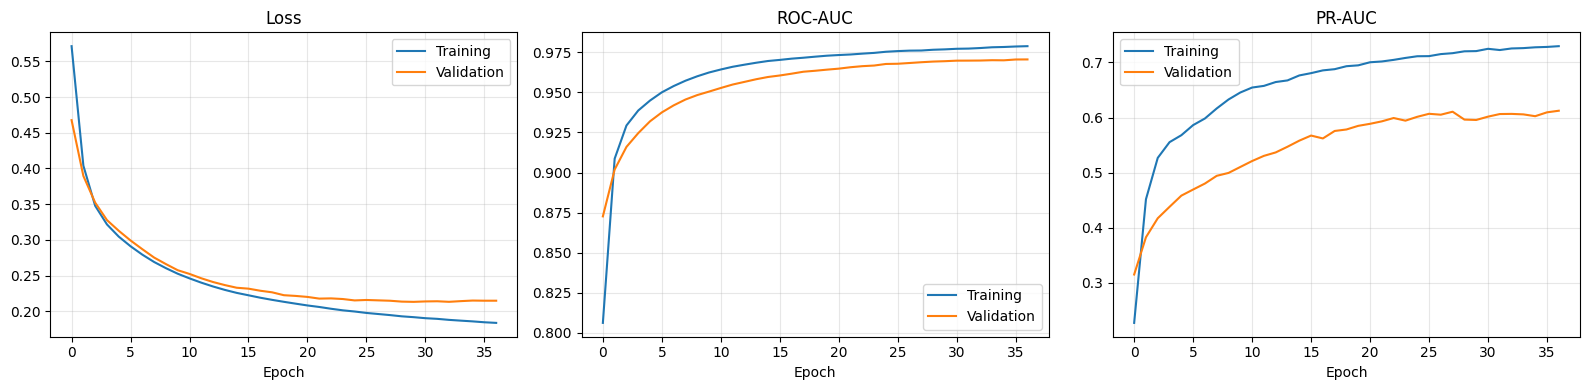

In [21]:

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

metrics = [
    ("loss", "Loss"),
    ("roc_auc", "ROC-AUC"),
    ("pr_auc", "PR-AUC")
]

for ax, (metric, title) in zip(axes, metrics):
    ax.plot(history.history[metric], label="Training")
    ax.plot(history.history[f"val_{metric}"], label="Validation")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()



**Findings:**
- Training and validation loss decreased during early epochs.
- Validation loss stabilized and slightly increased toward the end.
- ROC-AUC remained strong on validation data (around 0.97).
- A training-validation PR-AUC gap suggests mild overfitting.
- Early stopping restored the best weights based on validation loss.



## 25. Initial Model Comparison

We compare Logistic Regression, Random Forest, and ANN using the same validation data and a 0.5 decision threshold.

Final model selection will consider reliability, threshold sensitivity, and business costs.


In [22]:

models = {
    "Logistic Regression": lr_val_prob,
    "Random Forest": rf_val_prob,
    "ANN": ann_val_prob
}

comparison = []

for name, probabilities in models.items():
    predictions = (probabilities >= 0.5).astype(int)

    comparison.append({
        "Model": name,
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions),
        "F1": f1_score(y_val, predictions),
        "ROC_AUC": roc_auc_score(y_val, probabilities),
        "PR_AUC": average_precision_score(y_val, probabilities)
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(4))


,Model,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Logistic Regression,0.1365,0.7255,0.2298,0.8750,0.3829
1,Random Forest,0.7857,0.4314,0.5570,0.9687,0.6647
2,ANN,0.2635,0.8627,0.4037,0.9696,0.6170



**Findings:**
- ANN achieved the highest recall (86.27%) and ROC-AUC (0.9696).
- Random Forest achieved the highest precision (78.57%), F1-score (0.5570), and PR-AUC (0.6647).
- No model is selected yet because threshold tuning and error-cost analysis are pending.



## 26. Random Forest Hyperparameter Tuning

We test different Random Forest settings to improve failure prediction.

- Tune tree depth, leaf size, and class weights.
- Use the validation set to compare models.
- Prioritize PR-AUC for rare failure detection.
- Keep the test set untouched.


In [23]:

from sklearn.model_selection import ParameterGrid

param_grid = {
    "max_depth": [None, 10, 20],
    "min_samples_leaf": [1, 3],
    "class_weight": ["balanced", "balanced_subsample"]
}

rf_tuning_results = []
best_rf = None
best_rf_score = -1

for params in ParameterGrid(param_grid):
    model = RandomForestClassifier(
        n_estimators=200,
        random_state=SEED,
        n_jobs=-1,
        **params
    )

    model.fit(X_train_tree, y_train)
    prob = model.predict_proba(X_val_tree)[:, 1]

    pr_auc = average_precision_score(y_val, prob)

    rf_tuning_results.append({
        **params,
        "PR_AUC": pr_auc,
        "ROC_AUC": roc_auc_score(y_val, prob)
    })

    if pr_auc > best_rf_score:
        best_rf_score = pr_auc
        best_rf = model

rf_tuning_df = pd.DataFrame(rf_tuning_results)
display(rf_tuning_df.sort_values("PR_AUC", ascending=False).round(4))

print("Best RF Validation PR-AUC:", round(best_rf_score, 4))


,class_weight,max_depth,min_samples_leaf,PR_AUC,ROC_AUC
10,balanced_subsample,20.0,1,0.6898,0.9712
6,balanced_subsample,NaN,1,0.6895,0.9713
4,balanced,20.0,1,0.6660,0.9690
0,balanced,NaN,1,0.6647,0.9687
7,balanced_subsample,NaN,3,0.6527,0.9687
11,balanced_subsample,20.0,3,0.6527,0.9687
1,balanced,NaN,3,0.6355,0.9761
5,balanced,20.0,3,0.6353,0.9762
9,balanced_subsample,10.0,3,0.6192,0.9728
2,balanced,10.0,1,0.6164,0.9715


Best RF Validation PR-AUC: 0.6898



**Findings:**
- Tested 12 Random Forest configurations.
- Best settings: max_depth=20, min_samples_leaf=1, class_weight=balanced_subsample.
- Validation PR-AUC improved from 0.6647 to 0.6898.
- Validation ROC-AUC improved from 0.9687 to 0.9712.
- Final performance must be verified on the held-out test set.



## 27. Tuned Random Forest Evaluation

We compare the original and tuned Random Forest models using the same validation data and a 0.5 threshold.

This helps determine whether hyperparameter tuning improved failure detection and reduced false alarms.


In [26]:

from sklearn.metrics import confusion_matrix
best_rf_val_prob = best_rf.predict_proba(X_val_tree)[:, 1]
best_rf_val_pred = (best_rf_val_prob >= 0.5).astype(int)

rf_results = []

for name, prob in [
    ("Original RF", rf_val_prob),
    ("Tuned RF", best_rf_val_prob)
]:
    pred = (prob >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()

    rf_results.append({
        "Model": name,
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred),
        "F1": f1_score(y_val, pred),
        "PR_AUC": average_precision_score(y_val, prob),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn
    })

display(pd.DataFrame(rf_results).round(4))


,Model,Precision,Recall,F1,PR_AUC,TP,FP,FN,TN
0,Original RF,0.7857,0.4314,0.5570,0.6647,22,6,29,1443
1,Tuned RF,0.8148,0.4314,0.5641,0.6898,22,5,29,1444



**Findings:**
- Tuned Random Forest improved precision from 78.57% to 81.48%.
- PR-AUC improved from 0.6647 to 0.6898.
- False positives decreased from 6 to 5.
- Recall remained unchanged at 43.14%, with 29 missed failures.
- Threshold analysis is still required to improve the balance between missed failures and false alarms.



## 28. Random Forest Threshold Sensitivity

We examine how different probability thresholds affect precision, recall, F1-score, and prediction errors.

This helps understand the trade-off between detecting failures and generating unnecessary inspection alerts.


In [27]:

threshold_results = []

for threshold in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]:
    pred = (best_rf_val_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred, zero_division=0),
        "F1": f1_score(y_val, pred, zero_division=0),
        "TP": tp,
        "FP": fp,
        "FN": fn
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))


,Threshold,Precision,Recall,F1,TP,FP,FN
0,0.1,0.4412,0.8824,0.5882,45,57,6
1,0.2,0.5781,0.7255,0.6435,37,27,14
2,0.3,0.6809,0.6275,0.6531,32,15,19
3,0.4,0.7632,0.5686,0.6517,29,9,22
4,0.5,0.8148,0.4314,0.5641,22,5,29
5,0.6,0.8421,0.3137,0.4571,16,3,35



**Findings:**
- Lower thresholds increased failure detection but also increased false alarms.
- Threshold 0.1 achieved the highest recall (88.24%).
- Threshold 0.3 achieved the highest F1-score (0.6531) among tested values.
- Threshold 0.5 missed 29 of 51 failures.
- Final threshold selection requires comparison across models and hypothetical business costs.



## 29. Logistic Regression Hyperparameter Tuning

We test different regularization strengths and class-weight settings.

The objective is to improve validation PR-AUC while keeping the same training and validation conditions.


In [28]:

lr_results = []
best_lr = None
best_lr_score = -1

for C in [0.01, 0.1, 1, 10]:
    for weight in [None, "balanced"]:

        model = LogisticRegression(
            C=C,
            class_weight=weight,
            max_iter=1000,
            random_state=SEED
        )

        model.fit(X_train_scaled, y_train)
        prob = model.predict_proba(X_val_scaled)[:, 1]

        score = average_precision_score(y_val, prob)

        lr_results.append({
            "C": C,
            "Class_Weight": str(weight),
            "PR_AUC": score,
            "ROC_AUC": roc_auc_score(y_val, prob)
        })

        if score > best_lr_score:
            best_lr_score = score
            best_lr = model

lr_tuning_df = pd.DataFrame(lr_results)
display(lr_tuning_df.sort_values("PR_AUC", ascending=False).round(4))

print("Best LR Validation PR-AUC:", round(best_lr_score, 4))


,C,Class_Weight,PR_AUC,ROC_AUC
3,0.10,balanced,0.3848,0.8749
6,10.00,None,0.3846,0.8632
4,1.00,None,0.3844,0.8622
5,1.00,balanced,0.3829,0.8750
7,10.00,balanced,0.3829,0.8750
2,0.10,None,0.3780,0.8589
1,0.01,balanced,0.3716,0.8727
0,0.01,None,0.3403,0.8588


Best LR Validation PR-AUC: 0.3848



**Findings:**
- Tested 8 Logistic Regression configurations.
- Best settings: C=0.1 and class_weight=balanced.
- Validation PR-AUC improved slightly from 0.3829 to 0.3848.
- The improvement is small and may reflect validation variability.
- Tuned Logistic Regression is retained for comparison.



## 30. Tuned Logistic Regression Evaluation

We evaluate the tuned Logistic Regression using the same validation data and 0.5 threshold.

We compare failure detection, false alarms, and overall classification performance with the original baseline.


In [29]:

best_lr_val_prob = best_lr.predict_proba(X_val_scaled)[:, 1]

lr_comparison = []

for name, prob in [
    ("Original LR", lr_val_prob),
    ("Tuned LR", best_lr_val_prob)
]:
    pred = (prob >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()

    lr_comparison.append({
        "Model": name,
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred),
        "F1": f1_score(y_val, pred),
        "PR_AUC": average_precision_score(y_val, prob),
        "TP": tp,
        "FP": fp,
        "FN": fn
    })

display(pd.DataFrame(lr_comparison).round(4))


,Model,Precision,Recall,F1,PR_AUC,TP,FP,FN
0,Original LR,0.1365,0.7255,0.2298,0.3829,37,234,14
1,Tuned LR,0.1370,0.7255,0.2305,0.3848,37,233,14



**Findings:**
- Tuned Logistic Regression achieved 13.70% precision and 72.55% recall.
- Both models detected 37 failures and missed 14.
- False positives decreased slightly from 234 to 233.
- Hyperparameter tuning provided only a marginal improvement.
- Further threshold analysis is needed before final model selection.



## 31. ANN Hyperparameter Tuning

We test an alternative ANN architecture with regularization to investigate whether validation performance improves.

The same data splits, preprocessing, and class weights are maintained. Model selection is based on validation metrics.


In [30]:

tf.keras.utils.set_random_seed(SEED)

ann_tuned = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_scaled.shape[1],)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

ann_tuned.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.AUC(name="roc_auc"),
        tf.keras.metrics.AUC(curve="PR", name="pr_auc")
    ]
)

early_stop_tuned = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True
)

history_tuned = ann_tuned.fit(
    X_train_scaled.astype("float32"),
    y_train,
    validation_data=(X_val_scaled.astype("float32"), y_val),
    epochs=50,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stop_tuned],
    verbose=0
)

ann_tuned_prob = ann_tuned.predict(
    X_val_scaled.astype("float32"), verbose=0
).ravel()

print("Tuned ANN Validation Results")
print("Precision:", round(precision_score(y_val, ann_tuned_prob >= 0.5, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, ann_tuned_prob >= 0.5), 4))
print("F1:", round(f1_score(y_val, ann_tuned_prob >= 0.5), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, ann_tuned_prob), 4))
print("PR-AUC:", round(average_precision_score(y_val, ann_tuned_prob), 4))
print("Epochs:", len(history_tuned.history["loss"]))


Tuned ANN Validation Results
Precision: 0.3359
Recall: 0.8627
F1: 0.4835
ROC-AUC: 0.9745
PR-AUC: 0.7285
Epochs: 46



**Findings:**
- Tuned ANN achieved PR-AUC of 0.7285, compared with 0.6170 for baseline ANN.
- Precision improved from 26.35% to 33.59%.
- Recall remained at 86.27%.
- F1-score improved from 0.4037 to 0.4835.
- The tuned ANN outperformed tuned Random Forest in validation PR-AUC.
- Further experiments are required to assess reliability and stability.



## 32. Tuned ANN Error Analysis

We examine the confusion matrix of the tuned ANN at threshold 0.5.

This shows how many machine failures were detected, missed, or incorrectly predicted.


Tuned ANN - Validation Errors
True Positives: 44
False Positives: 87
False Negatives: 7
True Negatives: 1362


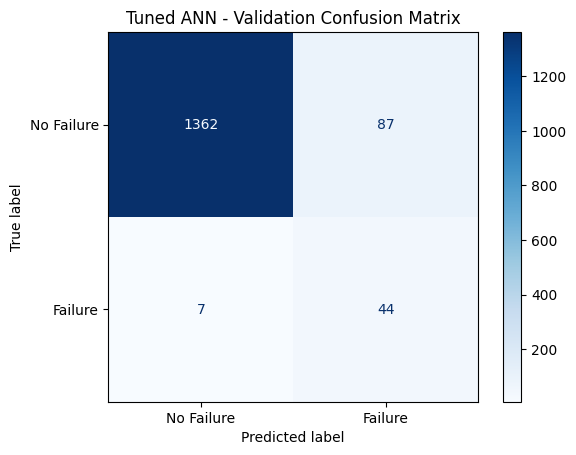

In [32]:

from sklearn.metrics import ConfusionMatrixDisplay
ann_tuned_pred = (ann_tuned_prob >= 0.5).astype(int)

cm = confusion_matrix(y_val, ann_tuned_pred)

tn, fp, fn, tp = cm.ravel()

print("Tuned ANN - Validation Errors")
print("True Positives:", tp)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Negatives:", tn)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Failure", "Failure"]
).plot(cmap="Blues")

plt.title("Tuned ANN - Validation Confusion Matrix")
plt.show()



**Findings:**
- Tuned ANN correctly detected 44 of 51 failures.
- Only 7 actual failures were missed.
- The model generated 87 false alarms at threshold 0.5.
- Recall is high (86.27%), but precision remains moderate (33.59%).
- Threshold and business-cost analysis are needed before final selection.



## 33. ANN Threshold Sensitivity

We evaluate different decision thresholds for the tuned ANN.

The goal is to understand how precision, recall, F1-score, and missed failures change without retraining the model.


In [33]:

ann_threshold_results = []

for threshold in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    pred = (ann_tuned_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()

    ann_threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred, zero_division=0),
        "F1": f1_score(y_val, pred, zero_division=0),
        "TP": tp,
        "FP": fp,
        "FN": fn
    })

ann_threshold_df = pd.DataFrame(ann_threshold_results)

display(ann_threshold_df.round(4))


,Threshold,Precision,Recall,F1,TP,FP,FN
0,0.1,0.1553,0.9804,0.2681,50,272,1
1,0.2,0.2034,0.9412,0.3345,48,188,3
2,0.3,0.2553,0.9412,0.4017,48,140,3
3,0.4,0.3007,0.9020,0.4510,46,107,5
4,0.5,0.3359,0.8627,0.4835,44,87,7
5,0.6,0.3805,0.8431,0.5244,43,70,8
6,0.7,0.4286,0.8235,0.5638,42,56,9
7,0.8,0.4884,0.8235,0.6131,42,44,9



**Findings:**
- Increasing the ANN threshold reduced false alarms.
- At threshold 0.8, ANN detected 42 of 51 failures.
- False positives decreased from 87 at threshold 0.5 to 44 at threshold 0.8.
- Threshold 0.8 achieved the highest F1-score (0.6131) among tested values.
- Final threshold selection requires business-cost analysis.



## 34. Adjusted Threshold Comparison

We compare tuned Random Forest and ANN at selected validation thresholds.

The objective is to examine the trade-off between failure detection, false alarms, and F1-score before cost-based model selection.


In [34]:

threshold_comparison = []

settings = [
    ("Tuned RF", best_rf_val_prob, 0.1),
    ("Tuned RF", best_rf_val_prob, 0.3),
    ("Tuned ANN", ann_tuned_prob, 0.8)
]

for name, prob, threshold in settings:
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()

    threshold_comparison.append({
        "Model": name,
        "Threshold": threshold,
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred),
        "F1": f1_score(y_val, pred),
        "TP": tp,
        "FP": fp,
        "FN": fn
    })

display(pd.DataFrame(threshold_comparison).round(4))


,Model,Threshold,Precision,Recall,F1,TP,FP,FN
0,Tuned RF,0.1,0.4412,0.8824,0.5882,45,57,6
1,Tuned RF,0.3,0.6809,0.6275,0.6531,32,15,19
2,Tuned ANN,0.8,0.4884,0.8235,0.6131,42,44,9



**Findings:**
- Random Forest at threshold 0.1 achieved the highest recall (88.24%).
- Random Forest at threshold 0.3 achieved the highest F1-score (0.6531).
- ANN at threshold 0.8 detected 42 failures with 44 false alarms.
- Different thresholds create different operational trade-offs.
- Final model selection requires reliability and business-cost evaluation.



## 35. Class Imbalance Handling — Random Oversampling

We compare class-weighted Random Forest with a model trained using random oversampling.

- Oversampling is applied only to training data.
- Validation data remains unchanged.
- The same Random Forest settings are used, except for class weighting.
- PR-AUC is used to compare rare-failure prediction performance.


In [35]:

from imblearn.over_sampling import RandomOverSampler

ros = RandomOverSampler(random_state=SEED)

X_train_ros, y_train_ros = ros.fit_resample(
    X_train_tree, y_train
)

print("Original Training Distribution:")
print(y_train.value_counts())

print("\nOversampled Training Distribution:")
print(pd.Series(y_train_ros).value_counts())

rf_ros = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=1,
    class_weight=None,
    random_state=SEED,
    n_jobs=-1
)

rf_ros.fit(X_train_ros, y_train_ros)

rf_ros_prob = rf_ros.predict_proba(X_val_tree)[:, 1]

print("\nValidation PR-AUC Comparison")
print("Class-weighted RF:",
      round(average_precision_score(y_val, best_rf_val_prob), 4))
print("Oversampled RF:",
      round(average_precision_score(y_val, rf_ros_prob), 4))


C:\Users\madhu\AppData\Roaming\Python\Python312\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\madhu\AppData\Roaming\Python\Python312\site-packages\sklearn\base.py:484: FutureWarning: `BaseEstimator._check_n_features` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_n_features` instead.
  warnings.warn(
C:\Users\madhu\AppData\Roaming\Python\Python312\site-packages\sklearn\base.py:493: FutureWarning: `BaseEstimator._check_feature_names` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_feature_names` instead.
  warnings.warn(


Original Training Distribution:
Machine failure
0    6763
1     237
Name: count, dtype: int64

Oversampled Training Distribution:
Machine failure
0    6763
1    6763
Name: count, dtype: int64

Validation PR-AUC Comparison
Class-weighted RF: 0.6898
Oversampled RF: 0.6969



**Findings:**
- Random oversampling increased failure-class training samples from 237 to 6,763.
- Oversampling was applied only to training data.
- Validation PR-AUC improved slightly from 0.6898 to 0.6969.
- The improvement is small and requires further evaluation.
- Validation and test data remain unchanged.



## 36. Oversampling Performance Comparison

We compare class-weighted and oversampled Random Forest models using the same validation data.

We examine precision, recall, F1-score, and prediction errors at different thresholds.


In [36]:

ros_comparison = []

for name, prob in [
    ("Class-weighted RF", best_rf_val_prob),
    ("Oversampled RF", rf_ros_prob)
]:
    for threshold in [0.1, 0.3, 0.5]:
        pred = (prob >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()

        ros_comparison.append({
            "Model": name,
            "Threshold": threshold,
            "Precision": precision_score(y_val, pred, zero_division=0),
            "Recall": recall_score(y_val, pred, zero_division=0),
            "F1": f1_score(y_val, pred, zero_division=0),
            "TP": tp,
            "FP": fp,
            "FN": fn
        })

display(pd.DataFrame(ros_comparison).round(4))


,Model,Threshold,Precision,Recall,F1,TP,FP,FN
0,Class-weighted RF,0.1,0.4412,0.8824,0.5882,45,57,6
1,Class-weighted RF,0.3,0.6809,0.6275,0.6531,32,15,19
2,Class-weighted RF,0.5,0.8148,0.4314,0.5641,22,5,29
3,Oversampled RF,0.1,0.3636,0.8627,0.5116,44,77,7
4,Oversampled RF,0.3,0.6102,0.7059,0.6545,36,23,15
5,Oversampled RF,0.5,0.7647,0.5098,0.6118,26,8,25



**Findings:**
- Oversampling improved recall at thresholds 0.3 and 0.5.
- At threshold 0.3, missed failures decreased from 19 to 15, but false alarms increased from 15 to 23.
- Class weighting performed better at threshold 0.1.
- Oversampling slightly improved PR-AUC, but neither approach was consistently superior.
- Both models are retained for business-cost evaluation.



## Phase 2 Summary — ML and ANN Development

### Models Developed
- Logistic Regression, Random Forest, and TensorFlow/Keras ANN.
- All models used the same training and validation splits.
- Model tuning and selection used validation data only.

### Best Validation PR-AUC
- Tuned Logistic Regression: 0.3848
- Tuned Random Forest: 0.6898
- Oversampled Random Forest: 0.6969
- Tuned ANN: 0.7285

### Key Observations
- Logistic Regression tuning produced minimal improvement.
- Random Forest tuning improved PR-AUC and precision.
- ANN tuning improved PR-AUC from 0.6170 to 0.7285.
- Random oversampling slightly improved Random Forest PR-AUC.
- Adjusting thresholds substantially changed recall and false alarms.

### Important Decisions
- Retain tuned Logistic Regression, both Random Forest variants, and tuned ANN for further comparison.
- Do not select a final model based only on PR-AUC or the default threshold.
- Keep the test dataset untouched until final evaluation.
- Conduct a separate controlled ANN experiment to assess performance stability.
